# Example 10: Reactions in the immobile water (dual-domain mass transfer)

A 1D column (28 cm) with a mobile and an immobile water domain. The two domains exchange solutes by first-order mass transfer, $\theta_m\,\partial C_m/\partial t = \ldots - \zeta (C_m - C_{im})$ and $\theta_{im}\,\partial C_{im}/\partial t = \zeta (C_m - C_{im}) + \theta_{im} R(C_{im})$. Water contents and the exchange coefficient are **constant**.

mf6rtm (`feature-ddmt`, reactive mode) computes:

- the transport in MODFLOW 6;
- the exchange as an exact first-order step;
- the reactions of the immobile water in a **second PhreeqcRM instance** with its own chemistry (`immobile_yaml`). This chemistry is written by its own `Mup3d` in another folder.

The mobile water has no reactions except aqueous speciation.

1. **Case 1: first-order Cl decay ($k$ = 20 d$^{-1}$) in the immobile water only.** It is implemented as a PHREEQC KINETICS rate (MgCl$_2$ removal, charge neutral). Reference: the same MODFLOW 6 model with the built-in **IST** package and first-order decay in the immobile domain. IST solves the exchange implicitly inside MODFLOW.
2. **Case 2: kinetic calcite dissolution in the immobile water only.** CO$_2$-rich water at pH 5 is injected into a column without calcite in the mobile pores; calcite (rate $k\,(1 - \mathrm{SR})$) exists only in the immobile domain. Reference: **PHREEQC TRANSPORT with stagnant cells** (`-stagnant 1 alpha theta_m theta_im`; PHREEQC's exchange factor $\alpha$ in s$^{-1}$ equals $\zeta$), with the same solutions, rate law and grid. PHREEQC is run through the IPhreeqc utility instance of PhreeqcRM, so no separate PHREEQC executable is needed.

In [1]:
from pathlib import Path
import os
import re
import shutil
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flopy
import modflowapi
import phreeqcrm

from mf6rtm import utils, mup3d

prefix = "ex10"
dataws = Path.cwd() / "data"
databasews = Path.cwd() / "database"
database = databasews / "pht3d_datab.dat"
binws = Path.cwd() / "bin"
ws = Path.cwd() / prefix
ws.mkdir(exist_ok=True)

osdir = {"Darwin": "mac", "Linux": "linux", "Windows": "win"}[platform.system()]
libext = {"mac": ".dylib", "linux": ".so", "win": ".dll"}[osdir]
libmf6 = Path(os.environ.get("MF6RTM_LIBMF6", binws / osdir / f"libmf6{libext}"))
assert libmf6.exists(), f"libmf6 not found at {libmf6}: fetch the binaries (see readme) or set MF6RTM_LIBMF6"

# series colors (categorical slots 1-3, fixed order); model identity by style: mf6rtm solid line, reference open markers
COL = {"x = 14 cm": "#2a78d6", "outlet": "#eb6834", "immobile, x = 14 cm": "#1baf7a", "no decay": "#1baf7a"}
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.6, "legend.frameon": False})

## Column, flow and dual-domain parameters

In [2]:
length_units, time_units = "meters", "days"
nlay, nrow, ncol = 1, 1, 56
Lx = 0.28                                    # m
delr, delc, top, botm = Lx / ncol, 1.0, 0.0, -1.0
k11 = k33 = 1.0
icelltype = 1
nouter, ninner, hclose, rclose, relax = 100, 300, 1e-8, 1e-8, 1.0

theta_m, theta_im, zeta = 0.35, 0.10, 2.0    # mobile and immobile water content (-), exchange coefficient (1/d)
dispersivity = 0.003                         # m
dt = 0.0025                                  # d
v = delr / dt                                # m/d: Courant number 1, as one PHREEQC shift per time step
q = v * theta_m                              # m3/d through the 1 m2 cross-section
tend = 1.5                                   # d
print(f"pore velocity {v:.2f} m/d, mobile residence time {Lx / v:.3f} d, exchange time theta_im/zeta = {theta_im / zeta:.3f} d")
print(f"zeta*dt/theta_im = {zeta * dt / theta_im:.3f}")

cells = {"x = 14 cm": ncol // 2 - 1, "outlet": ncol - 1}     # 0-based cell index (selected output: cell = index + 1)

# The transported Charge component changes sign here (background +0.12, inflow -0.12 mol/m3). Without an offset, the
# TVD advection of the negative values blows up at the outflow cell even without any reaction (checked with
# reactions off), so the charge offset of mf6rtm is used: Charge + offset stays positive in MODFLOW.
charge_offset = 1.0                          # mol/m3


def tdis(perlen):
    return [(p, int(round(p / dt)), 1.0) for p in perlen]

## Model builder (mf6rtm via Mup3d)

In [3]:
def build(run_ws, solutions_csv, perlen, sol_spd, porosity, kinetics=None, rates=""):
    """Mup3d + MODFLOW 6 model. kinetics: dict for mup3d.KineticPhases (all cells); rates: PHREEQC RATES text"""
    run_ws = Path(run_ws)
    if run_ws.exists():
        shutil.rmtree(run_ws)
    run_ws.mkdir(parents=True)
    sol = utils.solution_df_to_dict(pd.read_csv(solutions_csv, comment="#", index_col=0))
    solution = mup3d.Solutions(sol)
    solution.set_ic(1)
    model = mup3d.Mup3d(prefix, solution, nlay, nrow, ncol)
    model.set_wd(str(run_ws))
    model.set_database(str(database))
    model.set_charge_offset(charge_offset)       # before initialize(): applied to the initial and boundary Charge
    postfix = run_ws / "postfix.phqr"
    postfix.write_text(rates + (dataws / f"{prefix}_postfix.phqr").read_text())
    model.set_postfix(str(postfix))
    if kinetics is not None:
        kin = mup3d.KineticPhases({0: kinetics})
        kin.set_ic(1)
        model.set_phases(kin)
    model.initialize()
    wellchem = mup3d.ChemStress("wel")
    wellchem.set_spd(sol_spd)
    model.set_chem_stress(wellchem)

    nper = len(perlen)
    sim = flopy.mf6.MFSimulation(sim_name=prefix, sim_ws=str(run_ws), exe_name="mf6")
    flopy.mf6.ModflowTdis(sim, nper=nper, perioddata=tdis(perlen), time_units=time_units)
    gwf = flopy.mf6.ModflowGwf(sim, modelname="gwf", save_flows=True)
    ims = flopy.mf6.ModflowIms(sim, complexity="complex", outer_dvclose=hclose, outer_maximum=nouter,
                               inner_maximum=ninner, inner_dvclose=hclose, rcloserecord=rclose,
                               linear_acceleration="CG", relaxation_factor=relax, filename="gwf.ims")
    sim.register_ims_package(ims, [gwf.name])
    flopy.mf6.ModflowGwfdis(gwf, length_units=length_units, nlay=nlay, nrow=nrow, ncol=ncol, delr=delr, delc=delc,
                            top=top, botm=botm)
    flopy.mf6.ModflowGwfnpf(gwf, save_flows=True, save_saturation=True, icelltype=icelltype, k=k11, k33=k33,
                            save_specific_discharge=True)
    flopy.mf6.ModflowGwfic(gwf, strt=1.0)
    wel_spd = {sp: [[(0, 0, 0), q] + list(model.wel.data[sp][0])] for sp in range(nper)}
    flopy.mf6.ModflowGwfwel(gwf, stress_period_data=wel_spd, auxiliary=model.components, pname="wel")
    flopy.mf6.ModflowGwfchd(gwf, stress_period_data=[[(0, 0, ncol - 1), 1.0]])
    flopy.mf6.ModflowGwfoc(gwf, head_filerecord="gwf.hds", budget_filerecord="gwf.cbb",
                           saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")])
    for c in model.components:
        gwt = flopy.mf6.MFModel(sim, model_type="gwt6", modelname=c, model_nam_file=f"{c}.nam")
        imst = flopy.mf6.ModflowIms(sim, outer_dvclose=hclose, outer_maximum=nouter, inner_maximum=ninner,
                                    inner_dvclose=hclose, rcloserecord=rclose, linear_acceleration="BICGSTAB",
                                    relaxation_factor=relax, filename=f"{c}.ims")
        sim.register_ims_package(imst, [gwt.name])
        flopy.mf6.ModflowGwtdis(gwt, length_units=length_units, nlay=nlay, nrow=nrow, ncol=ncol, delr=delr,
                                delc=delc, top=top, botm=botm, filename=f"{c}.dis")
        flopy.mf6.ModflowGwtic(gwt, strt=model.sconc[c], filename=f"{c}.ic")
        flopy.mf6.ModflowGwtssm(gwt, sources=[["wel", "aux", c]], filename=f"{c}.ssm")
        flopy.mf6.ModflowGwtadv(gwt, scheme="tvd", filename=f"{c}.adv")
        flopy.mf6.ModflowGwtdsp(gwt, xt3d_off=True, alh=dispersivity, ath1=0.1 * dispersivity,
                                atv=0.1 * dispersivity, filename=f"{c}.dsp")
        flopy.mf6.ModflowGwtmst(gwt, porosity=porosity, filename=f"{c}.mst")
        flopy.mf6.ModflowGwtoc(gwt, concentration_filerecord=f"{c}.ucn", saverecord=[("CONCENTRATION", "ALL")])
        flopy.mf6.ModflowGwfgwt(sim, exgtype="GWF6-GWT6", exgmnamea="gwf", exgmnameb=c, filename=f"{c}.gwfgwt")
    sim.write_simulation(silent=True)
    return model


def run_ddmt(tag, solutions_csv, perlen, sol_spd, immobile_kinetics, rates):
    """reactive DDMT: mobile water without kinetics, immobile water with its own chemistry (own Mup3d, own folder)"""
    im = build(ws / f"immobile_chem_{tag}", solutions_csv, perlen, sol_spd, theta_m, kinetics=immobile_kinetics,
               rates=rates)
    model = build(ws / f"mf6rtm_{tag}", solutions_csv, perlen, sol_spd, theta_m, rates=rates)
    model.set_ddmt(theta_mobile=theta_m, theta_immobile=theta_im, alpham=zeta, mode="reactive",
                   immobile_initial="mobile", immobile_yaml=im.phreeqcyaml_file, output=True, output_format="csv")
    model.config.output["output_format"] = "csv"
    model.save_config()
    assert model.run(reactive=True, libname=str(libmf6), charge_offset=charge_offset)
    return model


def read_ucn(run_ws, comp):
    """concentration (mol/m3 = mmol/L) of a component at all cells and saved times"""
    ucn = flopy.utils.HeadFile(Path(run_ws) / f"{comp}.ucn", text="CONCENTRATION")
    times = np.array(ucn.get_times())
    return times, np.array([ucn.get_data(totim=t)[0, 0, :] for t in times])

## Case 1: first-order Cl decay in the immobile water (reference: MODFLOW 6 IST)

In [4]:
kdec = 20.0                                                        # 1/d
rates_decay = f"""RATES
Cl
-start
10 k = {kdec} / 86400          # 1/s
20 moles = -k * TOT("Cl") / 2 * TIME    # first-order Cl removal as MgCl2 (charge neutral)
30 SAVE moles
-end
"""
perlen1 = [0.1, 0.4] * 3                                           # three Cl pulses
spd1 = {i: [2] if i % 2 == 0 else [1] for i in range(len(perlen1))}
m1 = run_ddmt("decay", dataws / f"{prefix}_decay_solutions.csv", perlen1, spd1,
              {"Cl": {"formula": "Mg 1.0 Cl 2.0", "m": 1.0, "tol": 1e-10}}, rates_decay)


def run_ist(src_ws, tag, decay_cl=None):
    """reference: same MODFLOW 6 model with the IST package (MST porosity = theta_m + theta_im,
    IST volfrac = theta_im / (theta_m + theta_im), zetaim = zeta) and optional immobile first-order decay of Cl"""
    run_ws = ws / f"ist_{tag}"
    if run_ws.exists():
        shutil.rmtree(run_ws)
    shutil.copytree(src_ws, run_ws)
    sim = flopy.mf6.MFSimulation.load(sim_ws=str(run_ws), verbosity_level=0)
    for name in [m for m in sim.model_names if sim.get_model(m).model_type == "gwt6"]:
        g = sim.get_model(name)
        dec = (name.lower() == "cl") and decay_cl is not None
        mst_file = g.mst.filename
        g.remove_package("mst")                      # MF6 requires DECAY in MST as well (mobile rate 0)
        flopy.mf6.ModflowGwtmst(g, porosity=theta_m + theta_im, filename=mst_file,
                                **(dict(first_order_decay=True, decay=0.0) if dec else {}))
        flopy.mf6.ModflowGwtist(g, porosity=theta_m + theta_im, volfrac=theta_im / (theta_m + theta_im), zetaim=zeta,
                                cim=g.ic.strt.array, filename=f"{name}.ist",
                                **(dict(first_order_decay=True, decay=decay_cl, decay_sorbed=decay_cl) if dec else {}))
    sim.write_simulation(silent=True)
    mf6 = modflowapi.ModflowApi(str(libmf6), working_directory=str(run_ws))
    mf6.initialize()
    nsln = mf6.get_subcomponent_count()
    t, t_end = mf6.get_current_time(), mf6.get_end_time()
    while t < t_end:
        mf6.prepare_time_step(mf6.get_time_step())
        for sln in range(1, nsln + 1):
            mf6.prepare_solve(sln)
            for _ in range(nouter):
                if mf6.solve(sln):
                    break
            mf6.finalize_solve(sln)
        mf6.finalize_time_step()
        t = mf6.get_current_time()
    mf6.finalize()
    return read_ucn(run_ws, "Cl")


res1 = {"mf6rtm": read_ucn(m1.wd, "Cl"), "MF6 IST": run_ist(m1.wd, "decay", decay_cl=kdec),
        "no decay": run_ist(m1.wd, "nodecay")}

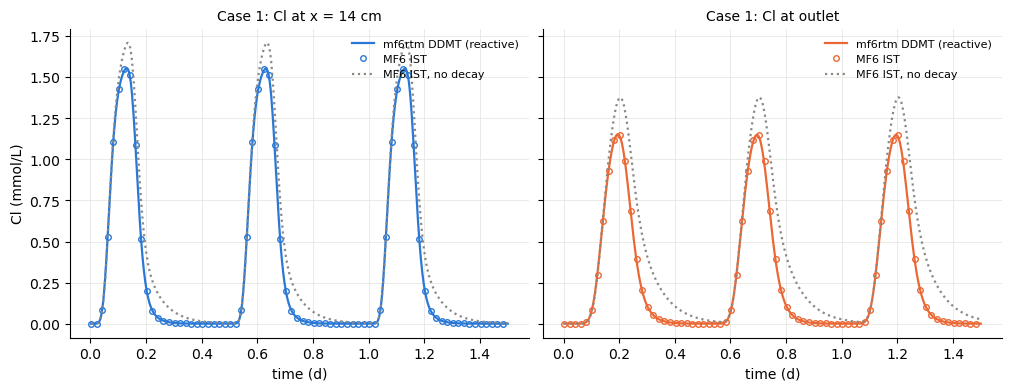

In [5]:
fig = plt.figure(figsize=(10, 3.8), layout="constrained")
axs = fig.subplots(1, 2, sharey=True)
for ax, (cname, ic) in zip(axs, cells.items()):
    t, c = res1["mf6rtm"]; ax.plot(t, c[:, ic], color=COL[cname], label="mf6rtm DDMT (reactive)")
    t, c = res1["MF6 IST"]; ax.plot(t[::8], c[::8, ic], "o", ms=4, mfc="none", mew=1.0, color=COL[cname], label="MF6 IST")
    t, c = res1["no decay"]; ax.plot(t, c[:, ic], ":", color="#8a8986", label="MF6 IST, no decay")
    ax.set_title(f"Case 1: Cl at {cname}", fontsize=10); ax.set_xlabel("time (d)")
axs[0].set_ylabel("Cl (mmol/L)")
for ax in axs:
    ax.legend(fontsize=8, loc="upper right")

## Case 2: kinetic calcite dissolution in the immobile water (reference: PHREEQC TRANSPORT with stagnant cells)

In [6]:
kcal, m_cal = 5e-8, 0.05                         # mol/kgw/s, initial calcite (mol per kgw of immobile water)
rates_calcite = f"""RATES
Calcite
-start
10 k = {kcal}                     # mol/kgw/s
20 rate = k * (1 - SR("Calcite"))
30 moles = rate * TIME
40 if (moles > M) then moles = M
50 SAVE moles
-end
"""
perlen2 = [tend]                                  # continuous injection of CO2-rich water (solution 2)
m2 = run_ddmt("calcite", dataws / f"{prefix}_calcite_solutions.csv", perlen2, {0: [2]},
              {"Calcite": {"m": m_cal, "tol": 1e-8}}, rates_calcite)

# mf6rtm results: mobile water from the selected output, immobile water from the DDMT output
sout = pd.read_csv(Path(m2.wd) / "sout.csv")
ddmt = pd.read_csv(Path(m2.wd) / "ddmt.csv")
print(sout.columns.tolist()[:12]); print(ddmt.columns.tolist()[:16])

In [7]:
def run_phreeqc_stagnant(mf6rtm_wd, tag):
    """PHREEQC TRANSPORT reference with the solutions written by Mup3d (phinp.dat of the mobile model):
    solution 2 = inflow (SOLUTION 0), solution 1 = initial water of all mobile and stagnant cells.
    Results are written with USER_PRINT into the PhreeqcRM output file (the utility instance writes no
    SELECTED_OUTPUT file)."""
    run_ws = ws / f"phreeqc_{tag}"
    if run_ws.exists():
        shutil.rmtree(run_ws)
    run_ws.mkdir()
    phinp = (Path(mf6rtm_wd) / "phinp.dat").read_text()
    blocks = {int(m.group(1)): m.group(0) for m in re.finditer(r"SOLUTION (\d+)\n.*?END\n", phinp, flags=re.S)}
    nst = 2 * ncol
    alpha_s = zeta / 86400.0                         # PHREEQC exchange factor (1/s)
    pqi = (blocks[2].replace("SOLUTION 2", "SOLUTION 0", 1) + blocks[1].replace("SOLUTION 1", f"SOLUTION 1-{nst}", 1)
           + f"KINETICS {ncol + 1}-{nst}\nCalcite\n    -m {m_cal}\n    -tol 1e-8\nEND\n" + rates_calcite + f"""
PRINT
    -reset false
    -user_print true
USER_PRINT
10 PRINT "@@", TOTAL_TIME, CELL_NO, -LA("H+"), TOT("Ca"), TOT("C(4)"), TOT("Cl")
TRANSPORT
    -cells {ncol}
    -shifts {int(round(tend / dt))}
    -time_step {dt * 86400.0}
    -flow_direction forward
    -boundary_conditions flux flux
    -lengths {ncol}*{delr}
    -dispersivities {ncol}*{dispersivity}
    -diffusion_coefficient 0.0
    -stagnant 1 {alpha_s} {theta_m} {theta_im}
    -print_cells {cells['x = 14 cm'] + 1} {ncol} {cells['x = 14 cm'] + 1 + ncol}
    -print_frequency 1
END
""")
    (run_ws / "reference.pqi").write_text(pqi)
    rm = phreeqcrm.PhreeqcRM(1, 1)
    rm.SetFilePrefix(str(run_ws / "phreeqc_ref"))
    rm.OpenFiles()
    rm.SetPrintChemistryOn(False, False, True)
    assert rm.LoadDatabase(str(database)) == 0
    assert rm.RunFile(False, False, True, str(run_ws / "reference.pqi")) == 0
    rm.CloseFiles()
    rows = [l.split()[1:] for l in (run_ws / "phreeqc_ref.chem.txt").read_text().splitlines() if l.startswith("@@")]
    df = pd.DataFrame(np.array(rows, dtype=float), columns=["time_s", "cell", "pH", "Ca", "C4", "Cl"])
    df = df.drop_duplicates(["time_s", "cell"], keep="last")
    df["time_d"] = df.time_s / 86400.0
    return df


ref2 = run_phreeqc_stagnant(m2.wd, "calcite")
ref2.head()

,time_s,cell,pH,Ca,C4,Cl,time_d
0,0.0,28.0,7.5000,0.001,0.002,0.0,0.0000
1,0.0,56.0,7.5000,0.001,0.002,0.0,0.0000
2,0.0,84.0,7.5000,0.001,0.002,0.0,0.0000
3,216.0,28.0,7.5001,0.001,0.002,0.0,0.0025
4,216.0,56.0,7.5000,0.001,0.002,0.0,0.0025


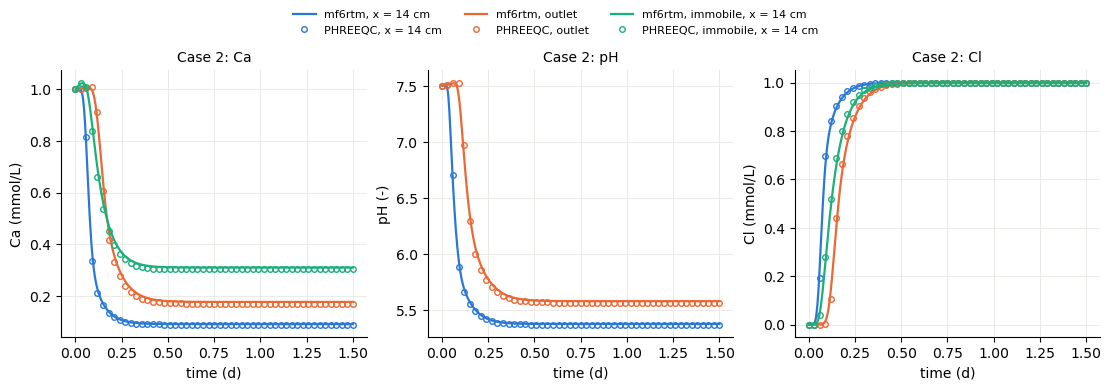

In [8]:
def mf6rtm_series(cname, var, domain="mobile"):
    ic = cells[cname]
    if domain == "mobile":
        d = sout[sout.cell == ic + 1].sort_values("time_d")       # selected output: cells numbered from 1
        return d.time_d.to_numpy(), d[var].to_numpy()
    comp = {"Ca": "Ca", "C4": "C", "Cl": "Cl"}[var]
    d = ddmt[(ddmt.domain == "immobile") & (ddmt.col == ic + 1)].sort_values("time_d")
    return d.time_d.to_numpy(), d[comp].to_numpy()


def phreeqc_series(cname, var, domain="mobile"):
    cell = cells[cname] + 1 + (ncol if domain == "immobile" else 0)
    d = ref2[ref2.cell == cell].sort_values("time_d")
    return d.time_d.to_numpy(), d[var].to_numpy()


series = [("x = 14 cm", "mobile"), ("outlet", "mobile"), ("x = 14 cm", "immobile")]
fig = plt.figure(figsize=(11, 3.8), layout="constrained")
axs = fig.subplots(1, 3)
for ax, (var, unit, scale) in zip(axs, (("Ca", "Ca (mmol/L)", 1e3), ("pH", "pH (-)", 1.0), ("Cl", "Cl (mmol/L)", 1e3))):
    for cname, dom in series:
        if var == "pH" and dom == "immobile":
            continue                                   # the DDMT output holds totals, not pH
        key = cname if dom == "mobile" else f"immobile, {cname}"
        t, y = mf6rtm_series(cname, var, dom); ax.plot(t, y * scale, color=COL[key], label=f"mf6rtm, {key}")
        t, y = phreeqc_series(cname, var, dom)
        ax.plot(t[::12], y[::12] * scale, "o", ms=4, mfc="none", mew=1.0, color=COL[key], label=f"PHREEQC, {key}")
    ax.set_xlabel("time (d)"); ax.set_ylabel(unit); ax.set_title(f"Case 2: {var}", fontsize=10)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=3, fontsize=8)

In [9]:
rows = []
# case 1 vs MF6 IST
for cname, ic in cells.items():
    t1, c1 = res1["mf6rtm"]; t2, c2 = res1["MF6 IST"]; c0 = res1["no decay"][1]
    d = c1[:, ic] - c2[:, ic]; peak = np.max(np.abs(c2[:, ic]))
    rows.append(dict(case="1 decay", variable="Cl", location=cname, reference="MF6 IST",
                     max_abs_dev_pct=100 * np.max(np.abs(d)) / peak, rmse_pct=100 * np.sqrt(np.mean(d ** 2)) / peak,
                     effect_pct=100 * np.max(np.abs(c2[:, ic] - c0[:, ic])) / np.max(c0[:, ic])))
# case 2 vs PHREEQC (deviation in % of the range of the reference over the run)
for cname, dom in series:
    for var in ("Ca", "pH", "Cl"):
        if var == "pH" and dom == "immobile":
            continue
        tm, ym = mf6rtm_series(cname, var, dom); tp, yp = phreeqc_series(cname, var, dom)
        sel = (tp > 0) & (tp <= tm.max())
        d = np.interp(tp[sel], tm, ym) - yp[sel]
        rng = np.ptp(yp[sel])
        rows.append(dict(case="2 calcite", variable=var, location=f"{dom}, {cname}", reference="PHREEQC stagnant",
                         max_abs_dev_pct=100 * np.max(np.abs(d)) / rng, rmse_pct=100 * np.sqrt(np.mean(d ** 2)) / rng,
                         effect_pct=np.nan))
metrics = pd.DataFrame(rows).round(2)
metrics.to_csv(ws / "ex10_metrics.csv", index=False)
metrics

,case,variable,location,reference,max_abs_dev_pct,rmse_pct,effect_pct
0,1 decay,Cl,x = 14 cm,MF6 IST,1.62,0.52,13.09
1,1 decay,Cl,outlet,MF6 IST,2.11,0.78,25.77
2,2 calcite,Ca,"mobile, x = 14 cm",PHREEQC stagnant,6.51,0.98,NaN
3,2 calcite,pH,"mobile, x = 14 cm",PHREEQC stagnant,12.33,1.38,NaN
4,2 calcite,Cl,"mobile, x = 14 cm",PHREEQC stagnant,6.00,0.87,NaN
5,2 calcite,Ca,"mobile, outlet",PHREEQC stagnant,5.57,1.49,NaN
6,2 calcite,pH,"mobile, outlet",PHREEQC stagnant,10.64,1.66,NaN
7,2 calcite,Cl,"mobile, outlet",PHREEQC stagnant,4.38,1.03,NaN
8,2 calcite,Ca,"immobile, x = 14 cm",PHREEQC stagnant,4.87,1.55,NaN
9,2 calcite,Cl,"immobile, x = 14 cm",PHREEQC stagnant,3.47,0.90,NaN


## Summary

- **Case 1: linear reaction, exact reference.** First-order Cl decay that acts only in the immobile water (PHREEQC KINETICS in the second PhreeqcRM instance) matches MODFLOW 6 IST with immobile decay. The maximum deviation is 1.6-2.1 % of the peak (RMSE ≤ 0.8 %), while the decay itself lowers the breakthrough by 13-26 % of the peak.
- **Case 2: non-linear geochemistry.** Kinetic calcite dissolution only in the immobile water matches PHREEQC TRANSPORT with stagnant cells for Ca, pH and Cl in the mobile water and for Ca and Cl in the immobile water. The RMSE is 0.9-1.7 % of the range of each variable, and the steady-state values agree. The largest single deviations (4-12 % of the range) occur at the steep fronts in the first 0.3 d, and to the same degree for the conservative Cl, so they come from the transport discretisation (MODFLOW 6 implicit with TVD vs. PHREEQC explicit shifts), not from the chemistry.
- **Immobile chemistry of its own.** The immobile YAML is written by its own `Mup3d` in another folder. PhreeqcRM resolves the database and chemistry files of a YAML relative to the working directory, so mf6rtm initialises the immobile instance from the YAML's folder (`feature-ddmt-reactive-immobile`).
- **Charge offset.** The transported Charge component changes sign in case 2. Without `set_charge_offset`, the TVD advection of the negative Charge values grows without bound at the outflow cell (to about -47 mol/m3 after 1.5 d, pH > 11). This happens also with DDMT and reactions switched off, so it is a general point for models with sign-changing Charge, not a DDMT issue. With an offset of 1 mol/m3 the results are as shown.